In [3]:
import pickle
import matplotlib.pyplot as plt
import numpy as np
        


In [4]:
with open("defunct_stage2_data.pkl", "rb") as f:
    sim_data = pickle.load(f)

frames = sim_data["frames"]
times = sim_data["times"]
region_history = sim_data["region_history"]



In [21]:
print(f"Frames          : {len(frames)}")
print(f"Times           : {len(times)}")
print(f"Region snapshots: {len(region_history)}")

Frames          : 121
Times           : 121
Region snapshots: 121


In [22]:
'''Now that the data set from the pickle is imorted as well we can now focus on the statistics based on the time evolution of the 
simulation. Before we start off with time evo make an test to check the first and the last frames to match their B0 and check wheter the imported
data is fine'''

G0 = frames[0]

print("Frame type :", type(G0))
print("Frame shape:", G0.shape)
print("Minimum B  :", np.min(G0))
print("Maximum B  :", np.max(G0))

G_fin = frames[-1]
print("Final minimum B :", np.min(G_fin))
print("Final maximum B :", np.max(G_fin))

Frame type : <class 'numpy.ndarray'>
Frame shape: (180, 360)
Minimum B  : -1344.8989323760638
Maximum B  : 1925.2278925263402
Final minimum B : -1019.6067294955283
Final maximum B : 1007.8263646609349


In [5]:
''' Now that it works we can make a proper dict to maintain all the parameters which will be calculated over the entire sim'''

statistics = {
    "time": [],
    "mean_abs_B": [],
    "max_abs_B": [],
    "positive_field": [],
    "negative_field":[],
    "net_field": [],
    "active_regions":[]

}

for G, t, regions in zip(frames,
times, region_history):

    positive = np.sum(G[G>0])
    negative = np.sum(G[G<0])

    statistics["time"].append(t)

    statistics["mean_abs_B"].append(np.mean(np.abs(G)))

    statistics["max_abs_B"].append(np.max(np.abs(G)))

    statistics["positive_field"].append(positive)

    statistics["negative_field"].append(negative)

    statistics["net_field"].append(positive + negative)

    statistics["active_regions"].append(len(regions))

    # here we are snapshoting a magnetgram with it's corresponding time and regions hence there are three arrays the frame
    # the time at eich it was taken and the regions
    

In [6]:
for key in statistics:
    statistics[key] = np.asarray(statistics[key])

print(statistics["time"].shape)
print(statistics["mean_abs_B"])


(121,)
[242.68126287 240.49212159 239.30011108 234.04879093 231.79902485
 230.8104657  228.891043   228.32409994 228.44946006 228.59897236
 229.15372854 227.58813093 228.02910605 228.26262037 227.13815546
 227.8264495  229.41943502 228.39076076 226.65534131 225.70214653
 223.20774015 219.69456785 221.49041519 222.07871606 219.77236986
 221.42438262 222.59733324 223.25580154 222.08492212 218.39092631
 219.49890536 220.46636518 220.79282054 220.06477563 218.14417398
 215.19278384 211.73300472 210.98726663 208.50171997 209.23955473
 211.31239404 210.85984023 213.03496633 212.49869539 211.53485678
 210.00113756 207.19475127 208.28517343 209.20388213 208.73739394
 208.89866013 208.18858196 207.04401469 204.08579874 202.04405291
 200.81744321 200.17856856 203.67534543 206.3868898  206.64907907
 206.41068134 205.31309293 201.32418057 198.94014176 198.16178802
 199.81904755 200.33368268 200.89024323 197.77405563 195.67286183
 197.83678445 195.64715099 194.69420723 195.1458419  195.32140335
 19

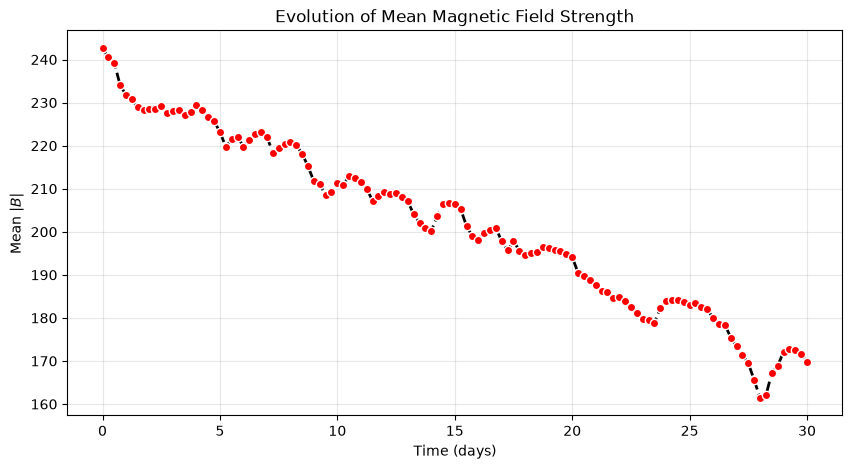

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(
    statistics["time"],
    statistics["mean_abs_B"],
    linewidth=2,
    linestyle ='--',
    zorder = 1,
    color = "black")
plt.scatter(
    statistics["time"],
    statistics["mean_abs_B"],
    color = "red",
    zorder =2,
    edgecolors ='white'
)

plt.xlabel("Time (days)")
plt.ylabel(r"Mean $|B|$")
plt.title("Evolution of Mean Magnetic Field Strength")

plt.grid(alpha=0.3)

plt.show()

The graph tells us the average magnitude of the magnetic field not to confuse with the mean signed field(which gives zero as its net magnetic field result)

This is the quatity being calculated $$\langle |B| \rangle = \frac{1}{N_{\text{pix}}} \sum_{i} |B_i|$$

Similarly we can also check the max magn field with decay and active regions (Do keep in mind that out simulation time is not enough to show the decay of the no. of active regions we calculated it to be approx 68 days and we do for 30 days for the sake of computational cost )




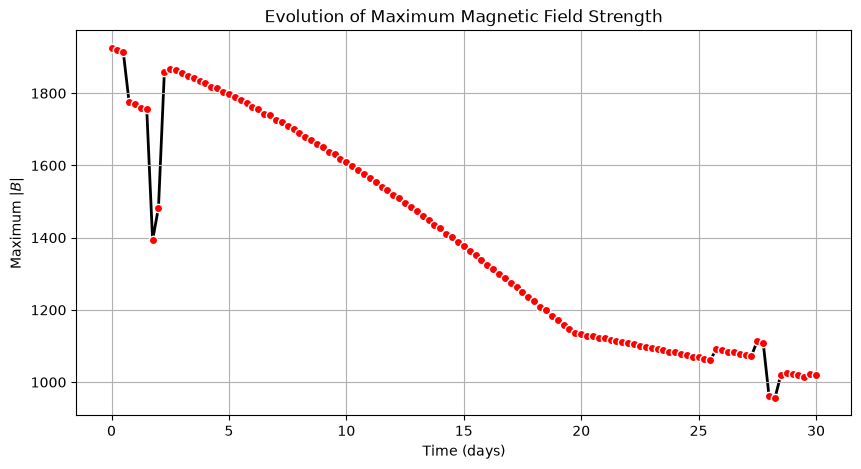

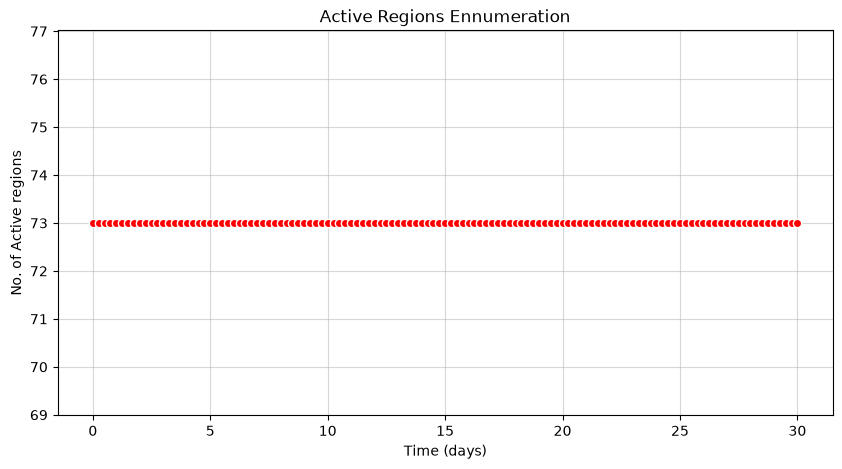

In [33]:
plt.figure(figsize=(10, 5))

plt.plot(
    statistics["time"],
    statistics["max_abs_B"],
    linewidth=2,
    zorder = 1,
    color = "black"
)

plt.scatter(
    statistics["time"],
    statistics["max_abs_B"],
    zorder = 2,
    color = "red",
    edgecolors = "white"
)
plt.xlabel("Time (days)")
plt.ylabel(r"Maximum $|B|$")
plt.title("Evolution of Maximum Magnetic Field Strength")

plt.grid(alpha=1)

plt.show()



plt.figure(figsize = (10,5))

plt.plot(
    statistics["time"],
    statistics["active_regions"],
    linewidth = 2,
    zorder = 1,
    color = "black"
    )
plt.scatter(
    statistics["time"],
    statistics["active_regions"],
    zorder = 2,
    color = "red",
    edgecolors="white"
)

plt.xlabel("Time (days)")

plt.ylabel("No. of Active regions")

plt.title("Active Regions Ennumeration")

plt.grid(alpha = 0.5)

plt.show()

TBF looking at the Max Magn field str plot the max starts at above 1800 even though our region str range is 600 to 1000

Which means that there is a spatioal overlap of the nregions which is being taken in to accord hence it is overcalculating which evidently visible in the sudden fall of the graph. Hmmmmm Gotta fix ask help from Sant or do some jugad...


I have a few suspicions on the flux calculations, since it is the sphere, i haven't considered the surface area element, this only struck me after the solid angle recon consideration. 
$$dA=R⊙2​cosλdλdϕ%% considering both the solar radius and the latitude we can check by defining the solar geometry once again

In [17]:
R_sun = 6.957e10
nlat, nlon = frames[0].shape
lat = np.linspace(-90,90,nlat)
lon = np.linspace(0,360,nlon, endpoint = False)

lat_rad = np.rad2deg(lat)

dlat = np.rad2deg(180/nlat)
dlon = np.rad2deg(360/nlon)

'''here if we try to directly combine a 1D list of length nlat with a 2D grid of size (lat array is (nlat,)) whereas for the magnetogram it is (nlat,nlon)
 nlat × nlon, python does not know how to align them and will crash with a shape mismatch error.
 Therefore we'd have to use a weighting factor which doesn't over represent any latitude, cuz near the poles the grid cells cover smaller physical area
 Basically we'd be broadcasting our operations between arrays of differerent dimensions'''

area_weight = np.cos(lat_rad)[:, np.newaxis]

def calc_flux(G):

    weighted_flux = G*area_weight

    flux = (
        R_sun**2 * np.sum(weighted_flux) * dlat * dlon
    )

    return flux

phi0 = calc_flux(frames[0])
phi_final = calc_flux(frames[-1])

print(f"Initial net flux : {phi0:.3e} Mx")
print(f"Final net flux   : {phi_final:.3e} Mx")

Initial net flux : 7.176e+28 Mx
Final net flux   : 4.043e+28 Mx


In [18]:
def calc_posi_neg_flux(G):

    positive_field = np.where(G > 0, G, 0)
    negative_field = np.where(G < 0, G, 0)

    positive_flux = (
        R_sun**2
        * np.sum(positive_field * area_weight)
        * dlat
        * dlon
    )

    negative_flux = (
        R_sun**2
        * np.sum(negative_field * area_weight)
        * dlat
        * dlon
    )

    return positive_flux, negative_flux


flux_statistics = {
    "time": [],
    "positive_flux": [],
    "negative_flux": [],
    "net_flux": []
}

for G, t in zip(frames, times):
    positive, negative = calc_posi_neg_flux(G)

    flux_statistics["time"].append(t)
    flux_statistics["positive_flux"].append(positive)
    flux_statistics["negative_flux"].append(negative)
    flux_statistics["net_flux"].append(positive + negative)

for key in flux_statistics:
    flux_statistics[key] = np.asarray(
        flux_statistics[key]
    )

In [19]:
print(
    f"Initial positive flux : "
    f"{flux_statistics['positive_flux'][0]:.3e} Mx"
)

print(
    f"Initial negative flux : "
    f"{flux_statistics['negative_flux'][0]:.3e} Mx"
)

print(
    f"Initial net flux      : "
    f"{flux_statistics['net_flux'][0]:.3e} Mx"
)


print(
    f"Final positive flux : "
    f"{flux_statistics['positive_flux'][-1]:.3e} Mx"
)

print(
    f"Final negative flux : "
    f"{flux_statistics['negative_flux'][-1]:.3e} Mx"
)

print(
    f"Final net flux      : "
    f"{flux_statistics['net_flux'][-1]:.3e} Mx"
)

Initial positive flux : -2.074e+29 Mx
Initial negative flux : 2.792e+29 Mx
Initial net flux      : 7.176e+28 Mx
Final positive flux : -1.421e+29 Mx
Final negative flux : 1.825e+29 Mx
Final net flux      : 4.043e+28 Mx


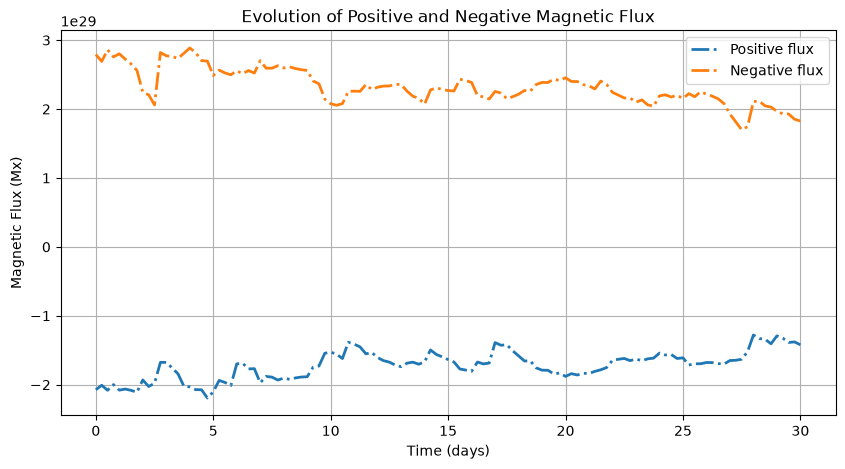

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(
    flux_statistics["time"],
    flux_statistics["positive_flux"],
    linewidth=2,
    label="Positive flux",
    linestyle = 'dashdot'
    
)

plt.plot(
    flux_statistics["time"],
    flux_statistics["negative_flux"],
    linewidth=2,
    label="Negative flux",
    linestyle = 'dashdot'
)

plt.xlabel("Time (days)")
plt.ylabel("Magnetic Flux (Mx)")
plt.title("Evolution of Positive and Negative Magnetic Flux")

plt.legend()
plt.grid(alpha=1)

plt.show()

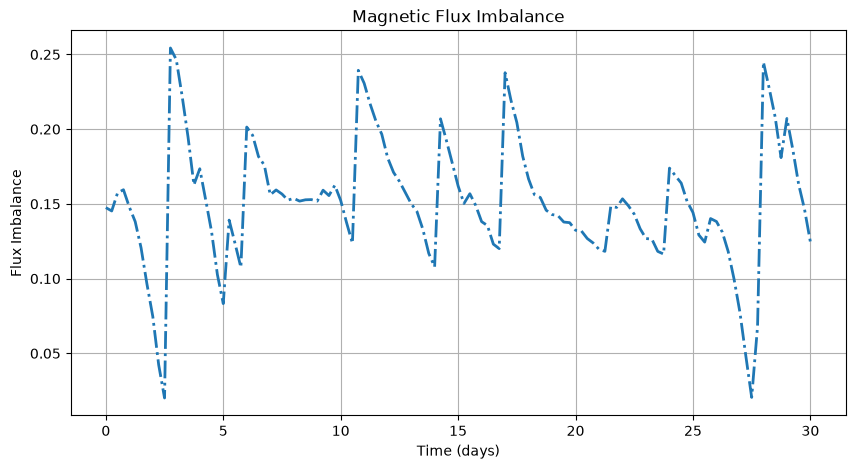

In [21]:
positive = flux_statistics["positive_flux"]
negative = flux_statistics["negative_flux"]

flux_imbalance = (
    np.abs(positive + negative)
    /
    (
        np.abs(positive)
        +
        np.abs(negative)
        +
        1e-30
    )
)

plt.figure(figsize=(10, 5))

plt.plot(
    flux_statistics["time"],
    flux_imbalance,
    linewidth=2,
    linestyle = 'dashdot'
)

plt.xlabel("Time (days)")
plt.ylabel("Flux Imbalance")
plt.title("Magnetic Flux Imbalance")

plt.grid(alpha=1)

plt.show()